In [30]:
# ============================================================
# TestData 1例でDVFスケールとWavelet再構成過程を診断
# 学習は行わない
# ============================================================

import math
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import voxelmorph as vxm

In [31]:
# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

FULL_SIZE = (128, 256, 256)
LOW_SIZE = (64, 128, 128)
COARSE_SIZE = (8, 16, 16)

# 80k Curriculum完了時のcheckpointを指定
CURRICULUM_80K_PATH = Path(
    r"D:\Saito\fullres_trilinear_short_20k_10k\model_fullres_trilinear_curriculum_20k_final.pth"
)

# TestDataのpairを指定
TEST_PAIR_DIR = Path(
    r"D:\Saito\Data\TestData\pair1"
)

OUTPUT_DIR = Path(
    "dvf_wavelet_diagnostic_pair1"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 人工的な正解DVFの最大変位量（full-resolution voxel単位）
ARTIFICIAL_SHIFT_VOX = 20.0

VIEW_Z_FULL = 64
VIEW_Z_LOW = 32

print("Device:", device)
print("Checkpoint:", CURRICULUM_80K_PATH)
print("Test pair:", TEST_PAIR_DIR)


Device: cuda:0
Checkpoint: D:\Saito\fullres_trilinear_short_20k_10k\model_fullres_trilinear_curriculum_20k_final.pth
Test pair: D:\Saito\Data\TestData\pair1


In [32]:

# ------------------------------------------------------------
# NPZ load
# ------------------------------------------------------------

def load_npz_volume(path):
    with np.load(path) as archive:
        if "Train" in archive:
            volume = archive["Train"]
        else:
            first_key = archive.files[0]
            volume = archive[first_key]

    volume = np.asarray(volume, dtype=np.float32)
    volume = np.squeeze(volume)

    # (256, 256, 128) -> (128, 256, 256)
    if volume.shape == (256, 256, 128):
        volume = np.transpose(volume, (2, 0, 1))

    if volume.shape != FULL_SIZE:
        raise ValueError(
            f"予期しない画像サイズ: {volume.shape}, "
            f"期待値: {FULL_SIZE}"
        )

    return volume


def natural_key(path):
    parts = re.split(r"(\d+)", path.name)
    return [
        int(part) if part.isdigit() else part.lower()
        for part in parts
    ]


def find_moving_file(pair_dir):
    files = sorted(
        pair_dir.glob("*.npz"),
        key=natural_key,
    )

    if len(files) != 2:
        raise RuntimeError(
            f"{pair_dir} にnpzが2枚必要です: {files}"
        )

    # registered / moving / _A_ をMovingとして優先
    for path in files:
        name = path.name.lower()
        if (
            "registered" in name
            or "moving" in name
            or "_a_" in name
        ):
            return path

    return files[0]



In [33]:

# ------------------------------------------------------------
# Haar Analysis
# 学習時と同じ: analysis -> ::2
# ------------------------------------------------------------

class Haar3DAnalysisOnly(nn.Module):
    def __init__(self):
        super().__init__()

        h_low = torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        h_high = torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
        ) / math.sqrt(2.0)

        filters = []
        names = []

        for z_name, z_filter in zip(
            ["L", "H"],
            [h_low, h_high],
        ):
            for y_name, y_filter in zip(
                ["L", "H"],
                [h_low, h_high],
            ):
                for x_name, x_filter in zip(
                    ["L", "H"],
                    [h_low, h_high],
                ):
                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )
                    filters.append(kernel)
                    names.append(
                        z_name + y_name + x_name
                    )

        self.register_buffer(
            "weight",
            torch.stack(filters, dim=0).unsqueeze(1),
        )
        self.names = names

    def forward(self, image):
        image = F.pad(
            image,
            (0, 1, 0, 1, 0, 1),
        )

        coefficients_full = F.conv3d(
            image,
            self.weight,
            stride=1,
            padding=0,
        )

        return coefficients_full[
            :,
            :,
            ::2,
            ::2,
            ::2,
        ]


analysis = Haar3DAnalysisOnly().to(device)
BAND_NAMES = analysis.names


In [34]:
# ------------------------------------------------------------
# Haar Synthesis
# ------------------------------------------------------------

def make_3d_filter(z_filter, y_filter, x_filter):
    return (
        z_filter[:, None, None]
        * y_filter[None, :, None]
        * x_filter[None, None, :]
    )


def create_synthesis_filters():
    h_low = torch.tensor(
        [1.0, 1.0],
        dtype=torch.float32,
        device=device,
    ) / math.sqrt(2.0)

    h_high = torch.tensor(
        [1.0, -1.0],
        dtype=torch.float32,
        device=device,
    ) / math.sqrt(2.0)

    filters = torch.stack(
        [
            make_3d_filter(h_low, h_low, h_low),
            make_3d_filter(h_low, h_low, h_high),
            make_3d_filter(h_low, h_high, h_low),
            make_3d_filter(h_low, h_high, h_high),
            make_3d_filter(h_high, h_low, h_low),
            make_3d_filter(h_high, h_low, h_high),
            make_3d_filter(h_high, h_high, h_low),
            make_3d_filter(h_high, h_high, h_high),
        ],
        dim=0,
    )

    # conv3dでのsynthesis用に反転
    return torch.flip(
        filters,
        dims=[1, 2, 3],
    ).unsqueeze(1)


SYNTHESIS_FILTERS = create_synthesis_filters()


def up_sampling_3d(coeff_low):
    """
    (B, 8, 64, 128, 128)
    -> (B, 8, 128, 256, 256)

    偶数座標へ係数を置き、残りはゼロ。
    """
    batch, channels, depth, height, width = coeff_low.shape

    coeff_up = torch.zeros(
        batch,
        channels,
        depth * 2,
        height * 2,
        width * 2,
        dtype=coeff_low.dtype,
        device=coeff_low.device,
    )

    coeff_up[:, :, ::2, ::2, ::2] = coeff_low

    return coeff_up


def synthesis_filter_3d(coeff_up):
    """
    coeff_up: (B, 8, 128, 256, 256)

    return:
        reconstructed : (B, 1, 128, 256, 256)
        filtered_bands: (B, 8, 128, 256, 256)
    """
    _, channels, depth, height, width = coeff_up.shape

    filters = SYNTHESIS_FILTERS.to(
        device=coeff_up.device,
        dtype=coeff_up.dtype,
    )

    filtered_bands = F.conv3d(
        coeff_up,
        filters,
        stride=1,
        padding=1,
        groups=channels,
    )

    filtered_bands = filtered_bands[
        :,
        :,
        :depth,
        :height,
        :width,
    ]

    reconstructed = torch.sum(
        filtered_bands,
        dim=1,
        keepdim=True,
    )

    return reconstructed, filtered_bands



In [35]:
# ------------------------------------------------------------
# DVF and spatial transformers
# ------------------------------------------------------------

transformer_low = vxm.layers.SpatialTransformer(
    LOW_SIZE
).to(device)

transformer_full = vxm.layers.SpatialTransformer(
    FULL_SIZE
).to(device)


def low_dvf_to_full_dvf(flow_low):
    """
    low voxel単位 -> full voxel単位。
    解像度が2倍なので移動量も2倍。
    """
    return F.interpolate(
        flow_low.float(),
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    ) * 2.0


def full_dvf_to_low_dvf(flow_full):
    """
    full voxel単位 -> low voxel単位。
    解像度が1/2なので移動量も1/2。
    """
    return F.interpolate(
        flow_full.float(),
        size=LOW_SIZE,
        mode="trilinear",
        align_corners=False,
    ) * 0.5


def gaussian_smooth_3d(flow, sigma=2.0):
    radius = max(1, int(math.ceil(3.0 * sigma)))

    coordinate = torch.arange(
        -radius,
        radius + 1,
        device=flow.device,
        dtype=flow.dtype,
    )

    kernel_1d = torch.exp(
        -(coordinate ** 2) / (2.0 * sigma ** 2)
    )
    kernel_1d = kernel_1d / kernel_1d.sum()

    channels = flow.shape[1]

    kernel_z = kernel_1d.view(
        1, 1, -1, 1, 1
    ).repeat(channels, 1, 1, 1, 1)

    kernel_y = kernel_1d.view(
        1, 1, 1, -1, 1
    ).repeat(channels, 1, 1, 1, 1)

    kernel_x = kernel_1d.view(
        1, 1, 1, 1, -1
    ).repeat(channels, 1, 1, 1, 1)

    flow = F.conv3d(
        flow,
        kernel_z,
        padding=(radius, 0, 0),
        groups=channels,
    )

    flow = F.conv3d(
        flow,
        kernel_y,
        padding=(0, radius, 0),
        groups=channels,
    )

    flow = F.conv3d(
        flow,
        kernel_x,
        padding=(0, 0, radius),
        groups=channels,
    )

    return flow


def make_artificial_true_dvf(batch_size, shift):
    """
    Curriculumと同様にfull-resolution正解DVFを作る。
    """
    coarse_flow = (
        torch.rand(
            batch_size,
            3,
            *COARSE_SIZE,
            device=device,
        ) * 2.0 - 1.0
    ) * shift

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    flow_full = F.interpolate(
        coarse_flow,
        size=FULL_SIZE,
        mode="trilinear",
        align_corners=False,
    )
    
    # 実験用：full解像度にだけ存在する細かいDVF
    fine_flow = gaussian_smooth_3d(
        torch.randn_like(flow_full),
        sigma=1.5,
    )

    fine_flow = fine_flow / (
        fine_flow.abs().amax(
            dim=(1, 2, 3, 4),
            keepdim=True,
        ) + 1e-8
    )

    flow_full = flow_full + 0.25 * fine_flow

    flow_low = full_dvf_to_low_dvf(flow_full)

    return flow_full, flow_low


def flow_statistics(name, flow):
    magnitude = torch.linalg.vector_norm(
        flow.float(),
        dim=1,
    )

    print(
        f"{name}\n"
        f"  shape        : {tuple(flow.shape)}\n"
        f"  abs mean     : {flow.abs().mean().item():.6f}\n"
        f"  magnitude μ  : {magnitude.mean().item():.6f} voxel\n"
        f"  magnitude max: {magnitude.max().item():.6f} voxel\n"
        f"  min / max    : "
        f"{flow.min().item():.6f} / "
        f"{flow.max().item():.6f}"
    )

In [36]:
# ------------------------------------------------------------
# Model and checkpoint
# ------------------------------------------------------------

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16],
]

model = vxm.networks.VxmDense_128_256_256(
    FULL_SIZE,
    nb_features,
    int_steps=0,
).to(device)

if not CURRICULUM_80K_PATH.exists():
    raise FileNotFoundError(
        f"80k checkpointがありません:\n"
        f"{CURRICULUM_80K_PATH}"
    )

try:
    checkpoint = torch.load(
        CURRICULUM_80K_PATH,
        map_location=device,
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(
        CURRICULUM_80K_PATH,
        map_location=device,
    )

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

if any(
    key.startswith("_orig_mod.")
    for key in state_dict
):
    state_dict = {
        key.replace("_orig_mod.", "", 1): value
        for key, value in state_dict.items()
    }

model.load_state_dict(
    state_dict,
    strict=True,
)

model.eval()

print("Model loaded.")



[64, 128, 128]
Model loaded.


In [37]:

# ------------------------------------------------------------
# Visualization helpers
# ------------------------------------------------------------

def show_8_bands(
    bands,
    z_index,
    title,
    output_path,
):
    """
    bands: (1, 8, D, H, W)
    """
    bands_np = bands[0].detach().float().cpu().numpy()
    z_index = min(z_index, bands_np.shape[1] - 1)

    vmax = np.percentile(
        np.abs(bands_np[:, z_index]),
        99,
    )
    vmax = max(float(vmax), 1e-8)

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(16, 8),
        constrained_layout=True,
    )

    for channel, axis in enumerate(axes.ravel()):
        axis.imshow(
            bands_np[channel, z_index],
            cmap="gray",
        )
        axis.set_title(BAND_NAMES[channel])
        axis.axis("off")

    fig.suptitle(title, fontsize=15)
    fig.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


def show_final_images(
    moving,
    teacher_full,
    teacher_wavelet,
    predicted_wavelet,
    output_path,
):
    z = min(VIEW_Z_FULL, moving.shape[2] - 1)

    images = [
        moving[0, 0, z].cpu().numpy(),
        teacher_full[0, 0, z].cpu().numpy(),
        teacher_wavelet[0, 0, z].cpu().numpy(),
        predicted_wavelet[0, 0, z].cpu().numpy(),
    ]

    titles = [
        "Moving",
        "Teacher: full-DVF STN",
        "Teacher: wavelet STN + synthesis",
        "Predicted-DVF wavelet output",
    ]

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(20, 5),
        constrained_layout=True,
    )

    for axis, image, title in zip(
        axes,
        images,
        titles,
    ):
        axis.imshow(
            image,
            cmap="gray",
        )
        axis.set_title(title)
        axis.axis("off")

    fig.suptitle(
        "Final reconstruction comparison",
        fontsize=15,
    )

    fig.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


Moving file: registered_masked_A_MIC00197_2018_0428.npz

========== DVF statistics ==========
GT low DVF
  shape        : (1, 3, 64, 128, 128)
  abs mean     : 0.170078
  magnitude μ  : 0.335716 voxel
  magnitude max: 0.788670 voxel
  min / max    : -0.684148 / 0.566360
Predicted low DVF
  shape        : (1, 3, 64, 128, 128)
  abs mean     : 0.228778
  magnitude μ  : 0.457023 voxel
  magnitude max: 1.381608 voxel
  min / max    : -1.315502 / 1.106609
GT full DVF
  shape        : (1, 3, 128, 256, 256)
  abs mean     : 0.340509
  magnitude μ  : 0.672157 voxel
  magnitude max: 1.604170 voxel
  min / max    : -1.401394 / 1.151579
Predicted full DVF
  shape        : (1, 3, 128, 256, 256)
  abs mean     : 0.456745
  magnitude μ  : 0.912550 voxel
  magnitude max: 2.740427 voxel
  min / max    : -2.593736 / 2.164942

========== Error checks ==========
GT residual DVF mean abs: 0.01202411949634552
GT residual DVF max abs: 0.08575630187988281
GT full-DVF vs low-only full-DVF MSE: 0.0002276115992

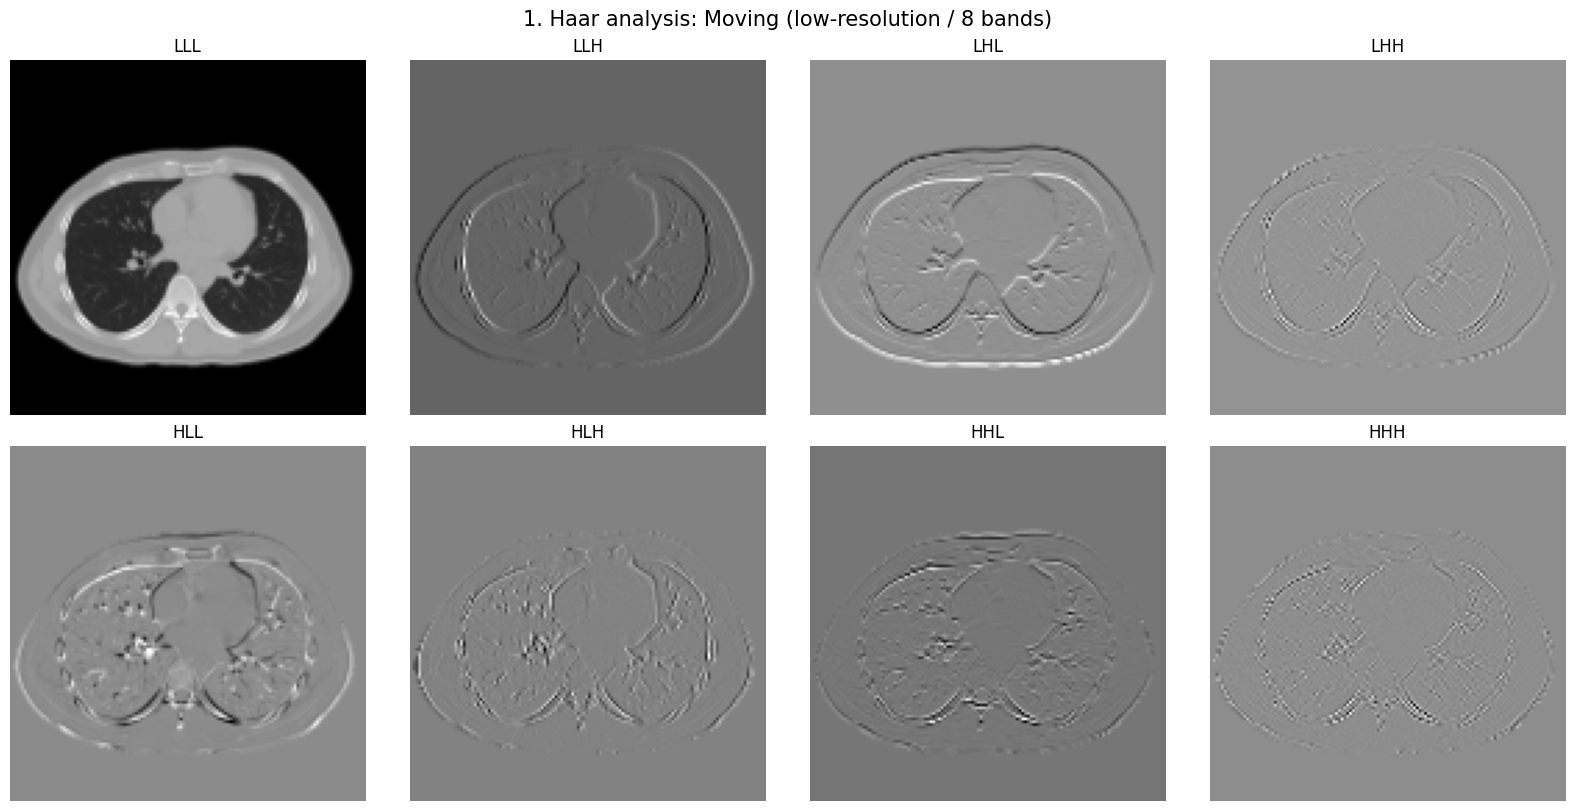

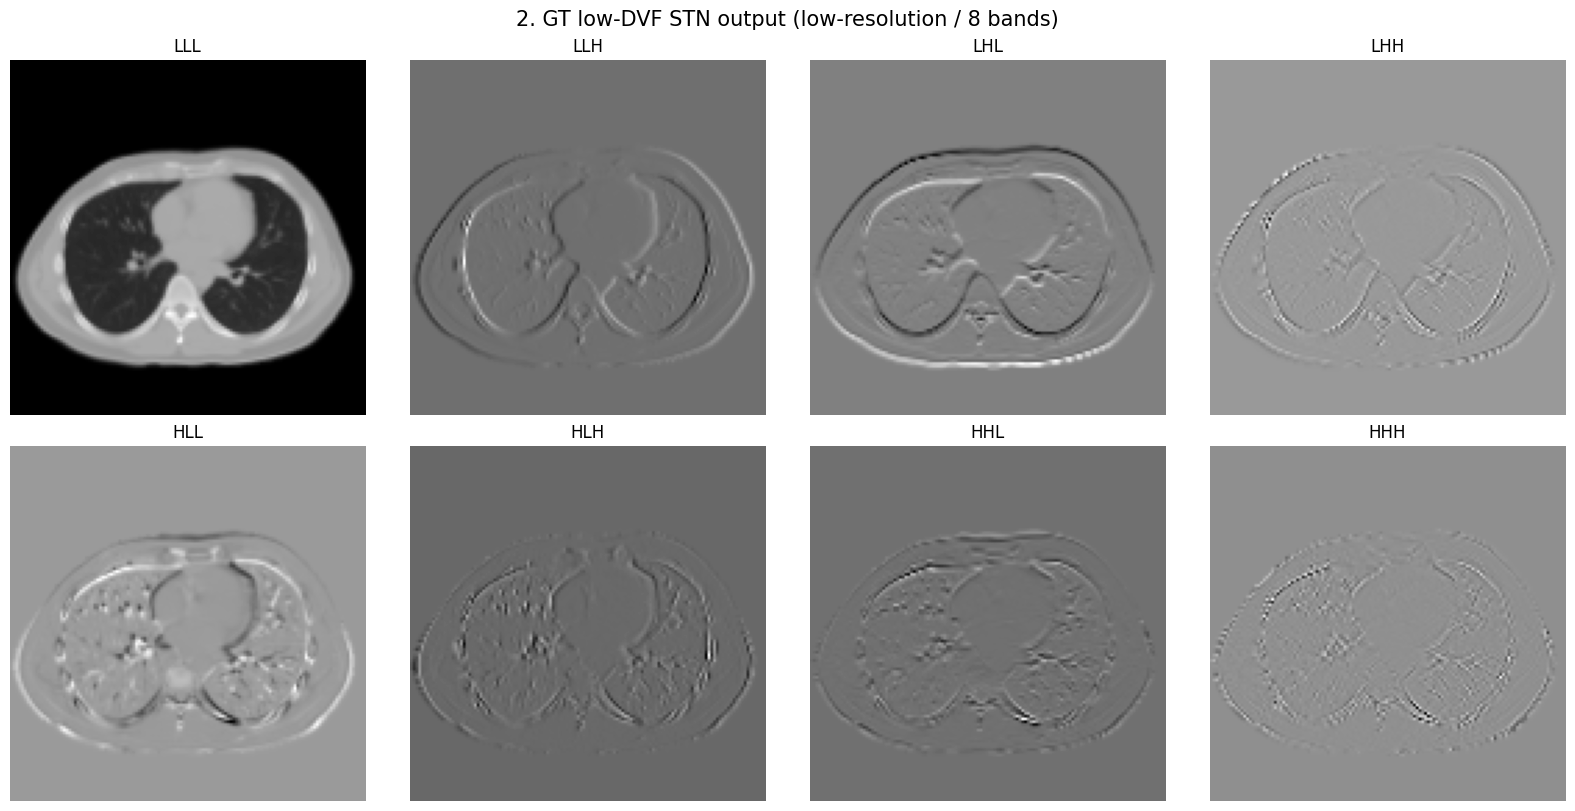

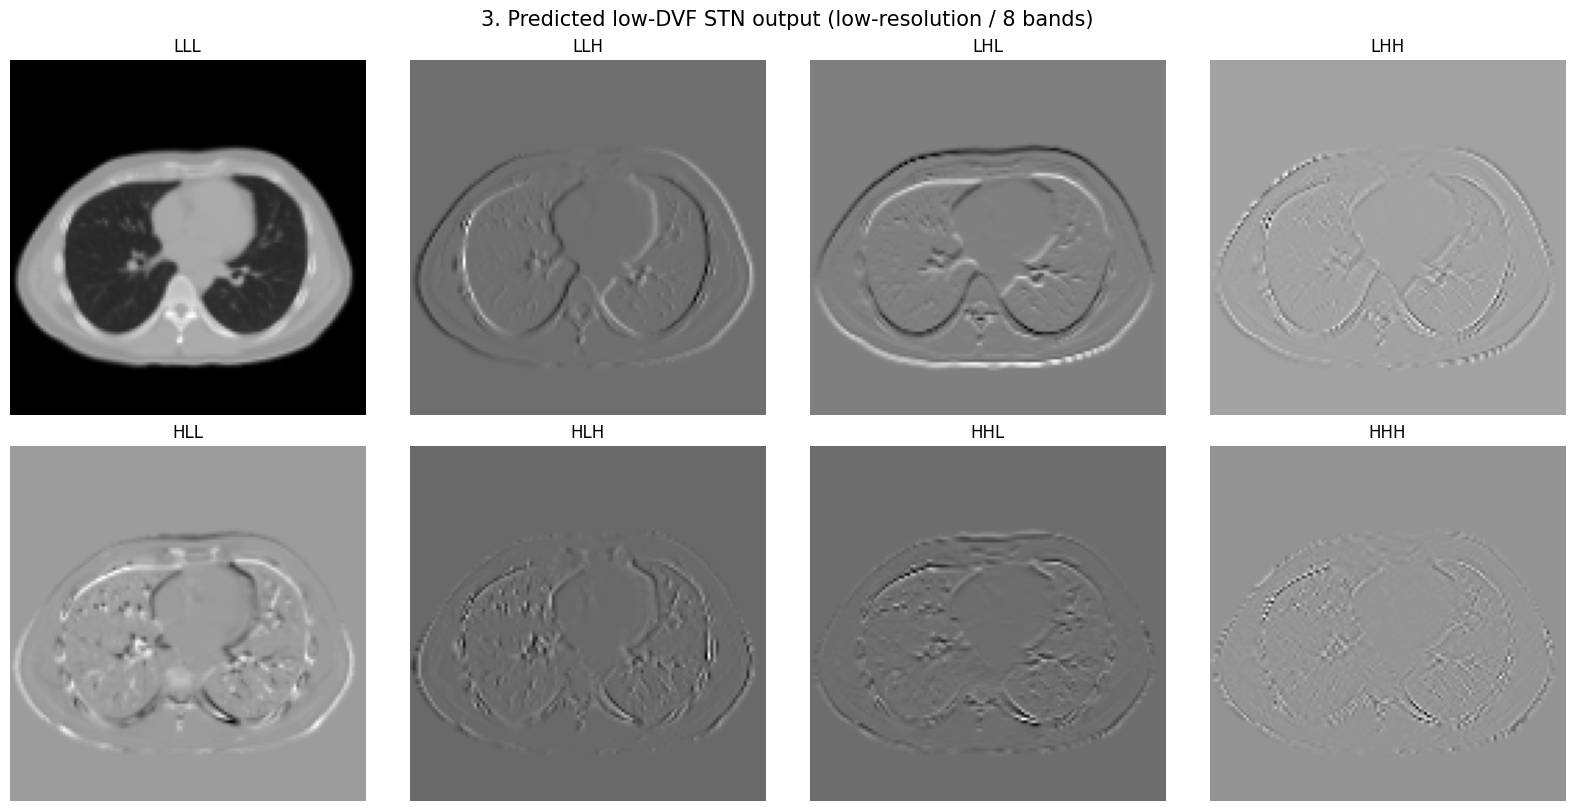

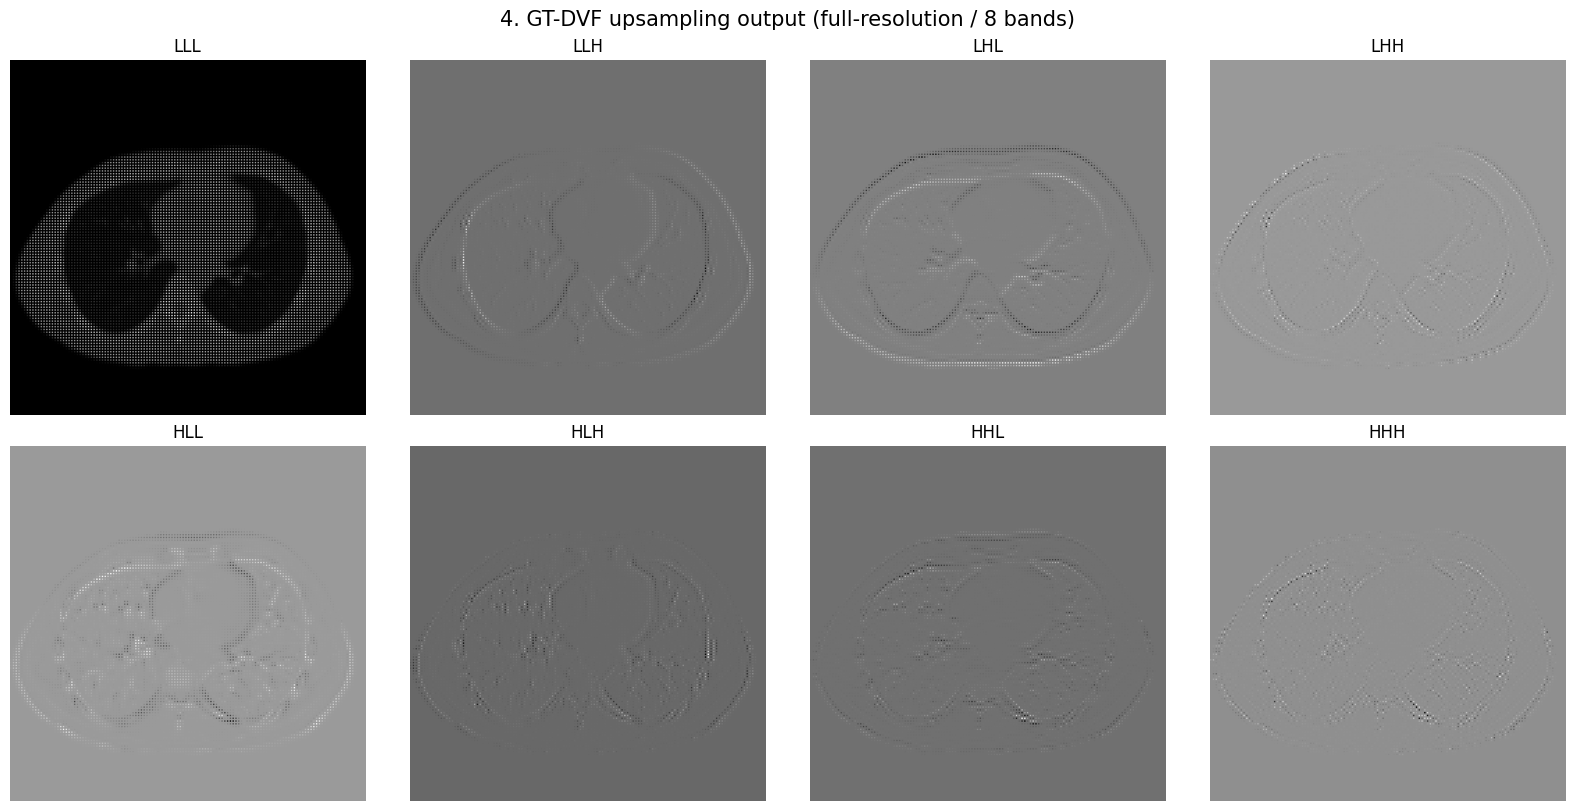

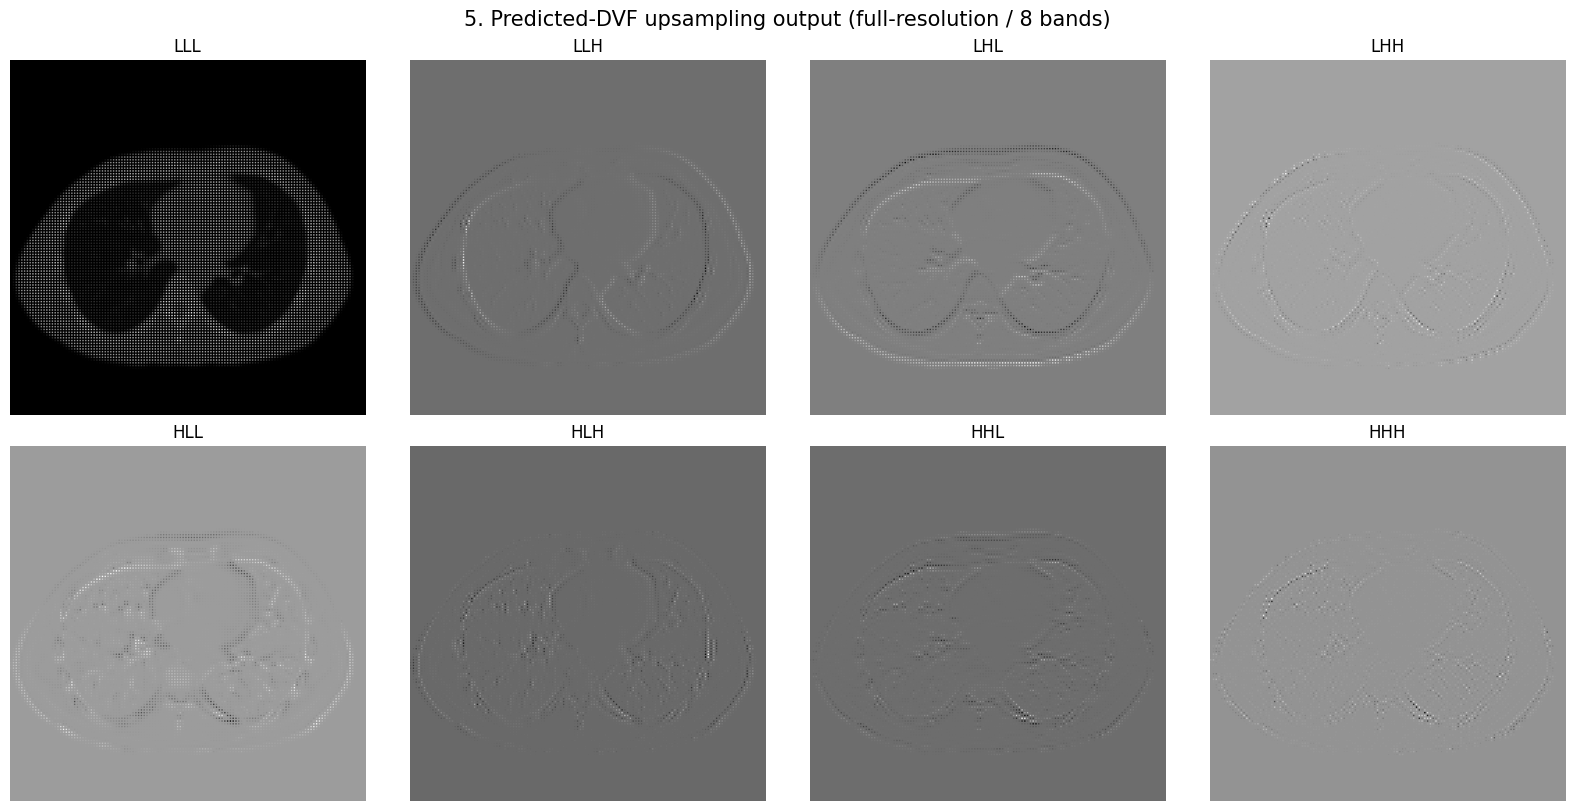

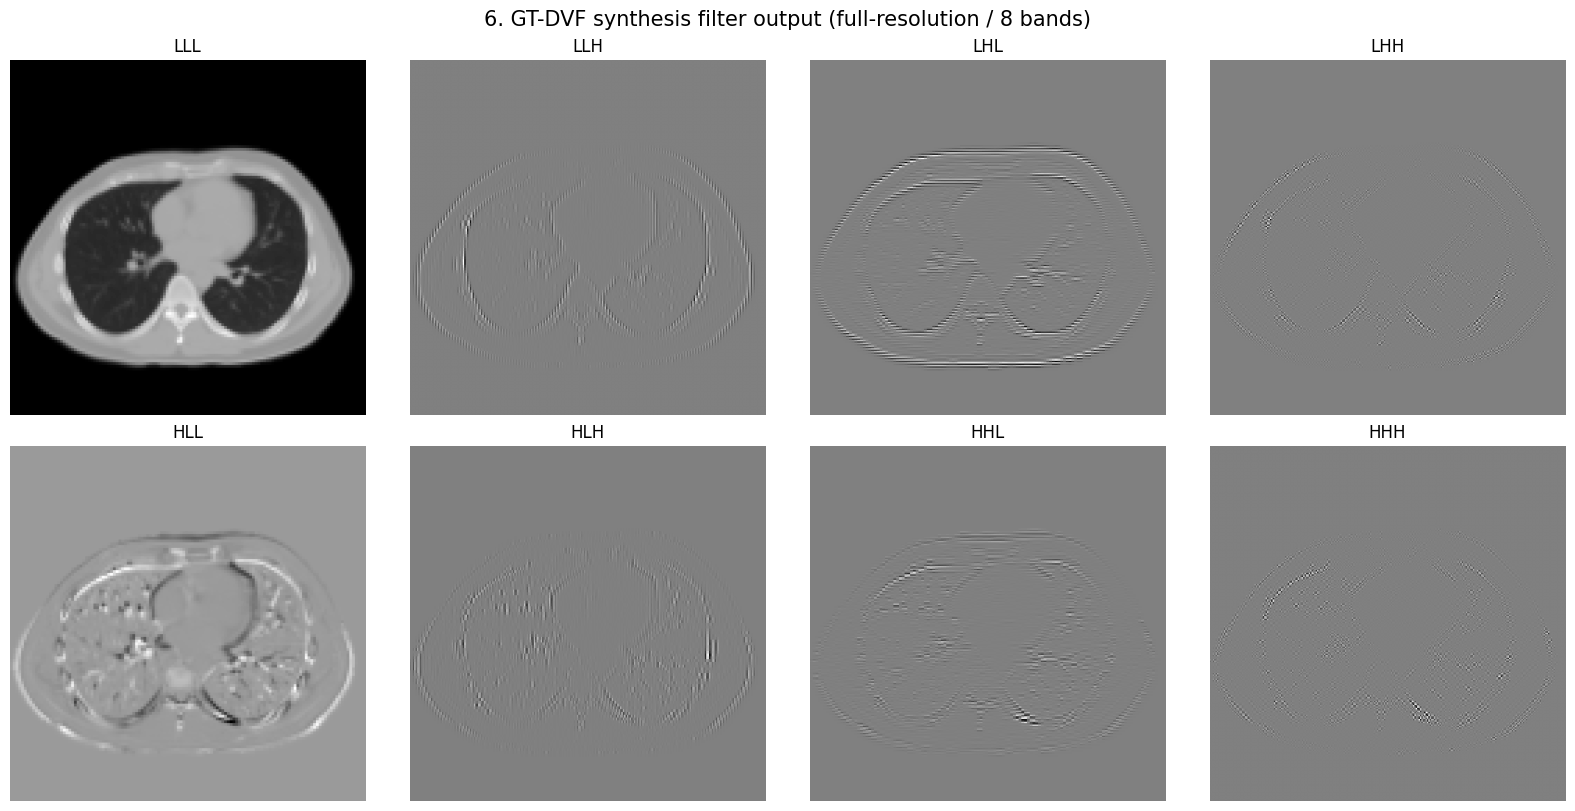

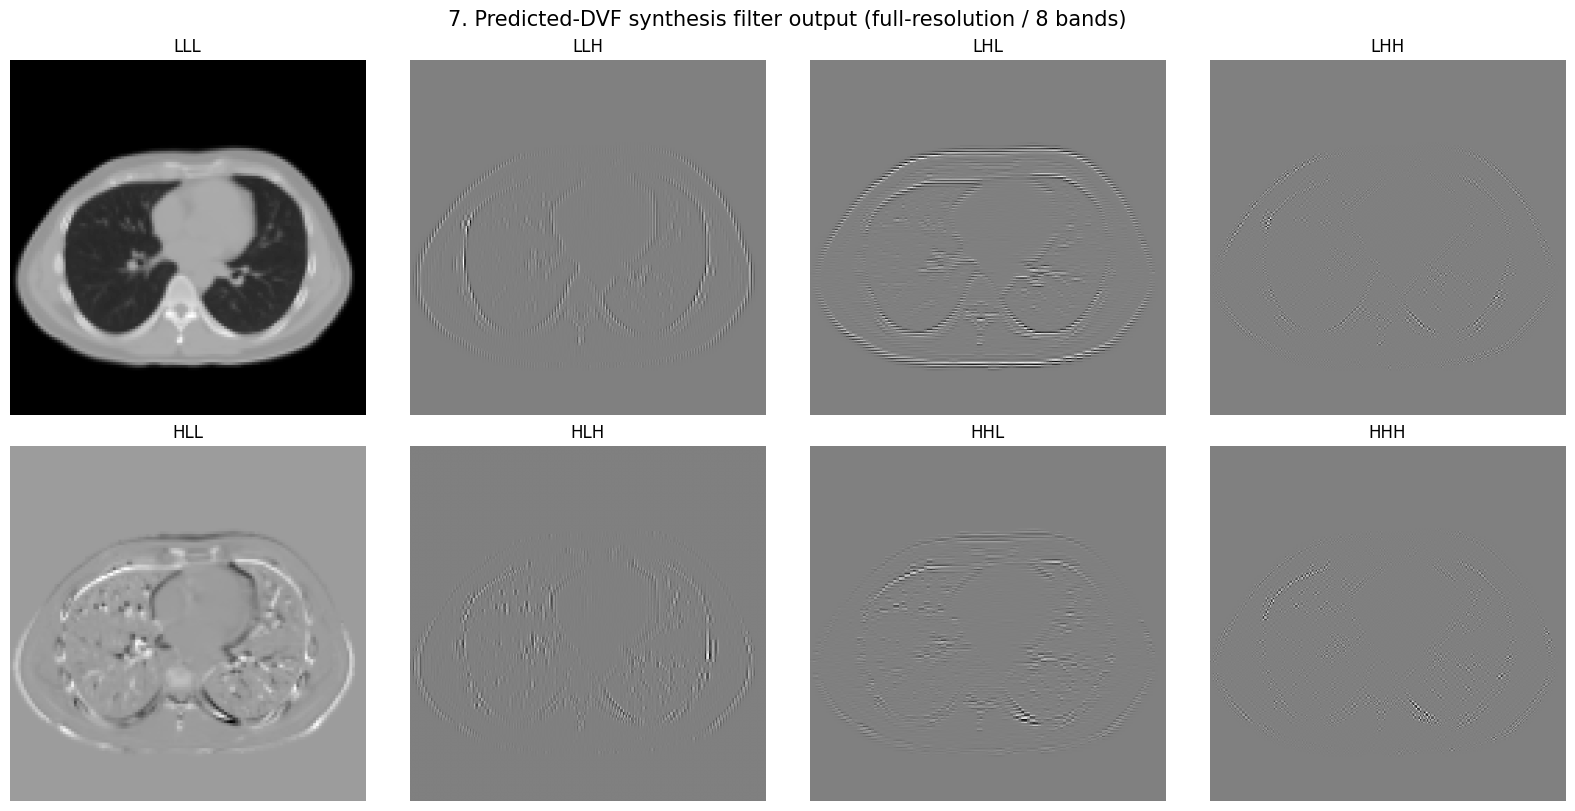

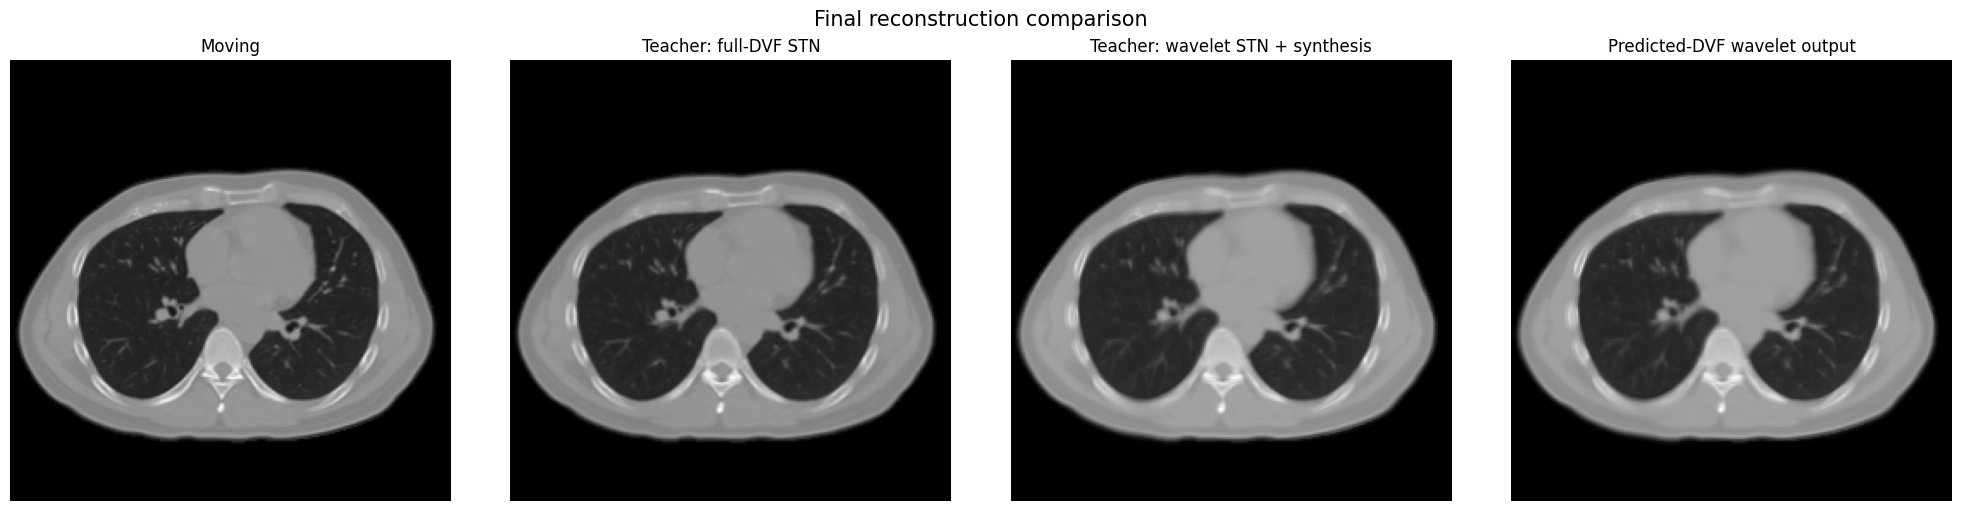


Saved diagnostic images:
D:\Saito\dvf_wavelet_diagnostic_pair1


In [38]:
# ============================================================
# Run one diagnostic case
# ============================================================

moving_path = find_moving_file(TEST_PAIR_DIR)

print("Moving file:", moving_path.name)

moving_np = load_npz_volume(moving_path)

moving = torch.from_numpy(
    moving_np
).unsqueeze(0).unsqueeze(0).to(
    device=device,
    dtype=torch.float32,
)

with torch.no_grad():
    # --------------------------------------------------------
    # 1. Artificial ground-truth full DVF
    # --------------------------------------------------------
    true_flow_full, true_flow_low = (
        make_artificial_true_dvf(
            batch_size=1,
            shift=ARTIFICIAL_SHIFT_VOX,
        )
    )

    # Curriculum時の教師画像:
    # full-resolution STNによるMovingの変形結果
    teacher_full = transformer_full(
        moving,
        true_flow_full,
    )

    # --------------------------------------------------------
    # 1-B. low DVFだけで作るfull DVF
    # --------------------------------------------------------
    flow_full_coarse = low_dvf_to_full_dvf(
        true_flow_low
    )

    # low DVFでは表せない細かいDVF成分
    flow_residual_gt = (
        true_flow_full - flow_full_coarse
    )

    # B: low DVFを補間しただけのfull-STN
    moved_low_only = transformer_full(
        moving,
        flow_full_coarse,
    )

    # C: 正解残差を足した場合（理論上限）
    flow_full_oracle = (
        flow_full_coarse + flow_residual_gt
    )

    moved_oracle = transformer_full(
        moving,
        flow_full_oracle,
    )

    # --------------------------------------------------------
    # 2. Haar analysis: 8 bands / low resolution
    # --------------------------------------------------------
    moving_w = analysis(moving)

    # --------------------------------------------------------
    # 3. 正解low-DVFで8周波数をSTN
    # --------------------------------------------------------
    true_warped_low = transformer_low(
        moving_w,
        true_flow_low,
    )

    # --------------------------------------------------------
    # 4. upsampling: 8 bands / full resolution
    # --------------------------------------------------------
    true_warped_up = up_sampling_3d(
        true_warped_low
    )

    # --------------------------------------------------------
    # 5. synthesis filter: 8 bands / full resolution
    # --------------------------------------------------------
    teacher_wavelet, true_filtered_bands = (
        synthesis_filter_3d(
            true_warped_up
        )
    )

    # --------------------------------------------------------
    # 6. 80k CurriculumモデルによるDVF予測
    #    学習時と同じ入力:
    #    Moving と full-STN教師画像
    # --------------------------------------------------------
    teacher_input_w = analysis(teacher_full)

    pred_flow_low = model(
        moving_w,
        teacher_input_w,
    )

    pred_flow_full = low_dvf_to_full_dvf(
        pred_flow_low
    )

    # --------------------------------------------------------
    # 7. 予測DVFを8周波数STNへ適用
    # --------------------------------------------------------
    pred_warped_low = transformer_low(
        moving_w,
        pred_flow_low,
    )

    # --------------------------------------------------------
    # 8. upsampling: 8 bands / full resolution
    # --------------------------------------------------------
    pred_warped_up = up_sampling_3d(
        pred_warped_low
    )

    # --------------------------------------------------------
    # 9. synthesis filter: 8 bands / full resolution
    # --------------------------------------------------------
    predicted_wavelet, pred_filtered_bands = (
        synthesis_filter_3d(
            pred_warped_up
        )
    )

    # --------------------------------------------------------
    # Numeric checks
    # --------------------------------------------------------
    print("\n========== DVF statistics ==========")

    flow_statistics(
        "GT low DVF",
        true_flow_low,
    )
    flow_statistics(
        "Predicted low DVF",
        pred_flow_low,
    )
    flow_statistics(
        "GT full DVF",
        true_flow_full,
    )
    flow_statistics(
        "Predicted full DVF",
        pred_flow_full,
    )

    print("\n========== Error checks ==========")
    
    print(
        "GT residual DVF mean abs:",
        flow_residual_gt.abs().mean().item(),
    )

    print(
        "GT residual DVF max abs:",
        flow_residual_gt.abs().max().item(),
    )

    print(
        "GT full-DVF vs low-only full-DVF MSE:",
        F.mse_loss(
            true_flow_full,
            flow_full_coarse,
        ).item(),
    )

    print(
        "DVF MSE (pred low vs GT low):",
        F.mse_loss(
            pred_flow_low.float(),
            true_flow_low.float(),
        ).item(),
    )

    print(
        "Teacher full-STN vs "
        "teacher wavelet reconstruction MSE:",
        F.mse_loss(
            teacher_full.float(),
            teacher_wavelet.float(),
        ).item(),
    )

    print(
        "Teacher full-STN vs "
        "predicted-DVF wavelet output MSE:",
        F.mse_loss(
            teacher_full.float(),
            predicted_wavelet.float(),
        ).item(),
    )

    print(
        "GT full-DVF vs low->full-DVF MSE:",
        F.mse_loss(
            true_flow_full.float(),
            low_dvf_to_full_dvf(
                true_flow_low
            ).float(),
        ).item(),
    )

    # --------------------------------------------------------
    # Save and display every requested stage
    # --------------------------------------------------------
    show_8_bands(
        moving_w,
        VIEW_Z_LOW,
        "1. Haar analysis: Moving "
        "(low-resolution / 8 bands)",
        OUTPUT_DIR / "01_moving_wavelet_low_8bands.png",
    )

    show_8_bands(
        true_warped_low,
        VIEW_Z_LOW,
        "2. GT low-DVF STN output "
        "(low-resolution / 8 bands)",
        OUTPUT_DIR / "02_gt_dvf_stn_low_8bands.png",
    )

    show_8_bands(
        pred_warped_low,
        VIEW_Z_LOW,
        "3. Predicted low-DVF STN output "
        "(low-resolution / 8 bands)",
        OUTPUT_DIR / "03_pred_dvf_stn_low_8bands.png",
    )

    show_8_bands(
        true_warped_up,
        VIEW_Z_FULL,
        "4. GT-DVF upsampling output "
        "(full-resolution / 8 bands)",
        OUTPUT_DIR / "04_gt_upsampled_full_8bands.png",
    )

    show_8_bands(
        pred_warped_up,
        VIEW_Z_FULL,
        "5. Predicted-DVF upsampling output "
        "(full-resolution / 8 bands)",
        OUTPUT_DIR / "05_pred_upsampled_full_8bands.png",
    )

    show_8_bands(
        true_filtered_bands,
        VIEW_Z_FULL,
        "6. GT-DVF synthesis filter output "
        "(full-resolution / 8 bands)",
        OUTPUT_DIR / "06_gt_synthesis_filtered_8bands.png",
    )

    show_8_bands(
        pred_filtered_bands,
        VIEW_Z_FULL,
        "7. Predicted-DVF synthesis filter output "
        "(full-resolution / 8 bands)",
        OUTPUT_DIR / "07_pred_synthesis_filtered_8bands.png",
    )

    show_final_images(
        moving,
        teacher_full,
        teacher_wavelet,
        predicted_wavelet,
        OUTPUT_DIR / "08_final_reconstruction_comparison.png",
    )

print("\nSaved diagnostic images:")
print(OUTPUT_DIR.resolve())

In [39]:
def compare_images(name, reference, image):
    difference = image.float() - reference.float()

    mae = difference.abs().mean().item()
    mse = (difference ** 2).mean().item()
    rmse = torch.sqrt((difference ** 2).mean()).item()

    reference_flat = reference.float().flatten()
    image_flat = image.float().flatten()

    ncc = torch.corrcoef(
        torch.stack([reference_flat, image_flat])
    )[0, 1].item()

    print(f"\n=== {name} ===")
    print(f"MAE : {mae:.8f}")
    print(f"MSE : {mse:.8f}")
    print(f"RMSE: {rmse:.8f}")
    print(f"NCC : {ncc:.8f}")


# Full-resolution正解DVFで直接warpした教師画像
# と、正解DVFを半分にしてwavelet STN→加算した画像の比較
compare_images(
    "GT full-STN vs GT wavelet-STN + summed image",
    teacher_full,
    teacher_wavelet,
)

# 正解DVF経路の加算後画像と、80kモデルのDVF経路の加算後画像の比較
compare_images(
    "GT summed image vs predicted-DVF summed image",
    teacher_wavelet,
    predicted_wavelet,
)

# Full-STN教師画像と、予測DVF経路の最終加算後画像の比較
compare_images(
    "GT full-STN vs predicted-DVF summed image",
    teacher_full,
    predicted_wavelet,
)

# A と B:
# low DVFだけで細かい変形を失うか
compare_images(
    "GT full-STN vs low-DVF-only full-STN",
    teacher_full,
    moved_low_only,
)

# A と C:
# 正解残差を足せば正解DVFへ戻るか
compare_images(
    "GT full-STN vs low-DVF + GT-residual full-STN",
    teacher_full,
    moved_oracle,
)


=== GT full-STN vs GT wavelet-STN + summed image ===
MAE : 0.00445863
MSE : 0.00020205
RMSE: 0.01421430
NCC : 0.99849069

=== GT summed image vs predicted-DVF summed image ===
MAE : 0.00138414
MSE : 0.00001833
RMSE: 0.00428154
NCC : 0.99982446

=== GT full-STN vs predicted-DVF summed image ===
MAE : 0.00473928
MSE : 0.00021799
RMSE: 0.01476458
NCC : 0.99840504

=== GT full-STN vs low-DVF-only full-STN ===
MAE : 0.00027527
MSE : 0.00000103
RMSE: 0.00101371
NCC : 0.99999201

=== GT full-STN vs low-DVF + GT-residual full-STN ===
MAE : 0.00000000
MSE : 0.00000000
RMSE: 0.00000000
NCC : 0.99999988


c:\Users\user\anaconda3\envs\nn\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\anaconda3\envs\nn\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 35299 (\N{CJK UNIFIED IDEOGRAPH-89E3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\anaconda3\envs\nn\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 12398 (\N{HIRAGANA LETTER NO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\anaconda3\envs\nn\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 12415 (\N{HIRAGANA LETTER MI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\anaconda3\envs\nn\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 12434 (\N{HIRAGANA LETTER WO}) missing from font(s)

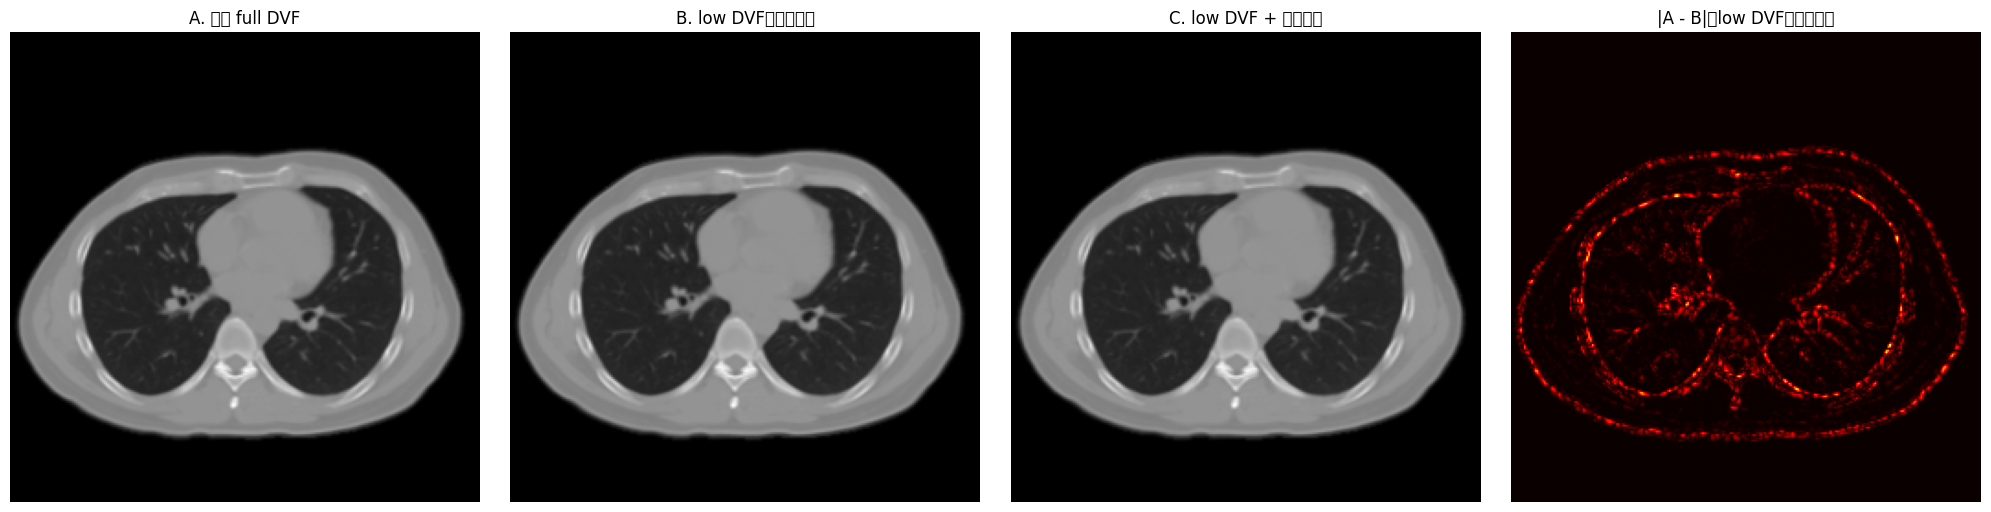

In [40]:
def show_residual_dvf_experiment(
    teacher_full,
    moved_low_only,
    moved_oracle,
):
    z = min(VIEW_Z_FULL, teacher_full.shape[2] - 1)

    images = [
        teacher_full[0, 0, z].cpu().numpy(),
        moved_low_only[0, 0, z].cpu().numpy(),
        moved_oracle[0, 0, z].cpu().numpy(),
        np.abs(
            teacher_full[0, 0, z].cpu().numpy()
            - moved_low_only[0, 0, z].cpu().numpy()
        ),
    ]

    titles = [
        "A. 正解 full DVF",
        "B. low DVFのみを補間",
        "C. low DVF + 正解残差",
        "|A - B|：low DVFで失った差",
    ]

    fig, axes = plt.subplots(
        1, 4, figsize=(20, 5),
        constrained_layout=True,
    )

    for ax, image, title in zip(axes, images, titles):
        if title == "|A - B|：low DVFで失った差":
            ax.imshow(image, cmap="hot", vmin=0)
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")

    plt.show()
    plt.close(fig)


show_residual_dvf_experiment(
    teacher_full,
    moved_low_only,
    moved_oracle,
)

In [41]:
def show_summed_comparison(
    teacher_full,
    teacher_wavelet,
    predicted_wavelet,
    output_path,
):
    z = min(VIEW_Z_FULL, teacher_full.shape[2] - 1)

    full_np = teacher_full[0, 0, z].cpu().numpy()
    gt_sum_np = teacher_wavelet[0, 0, z].cpu().numpy()
    pred_sum_np = predicted_wavelet[0, 0, z].cpu().numpy()

    gt_difference = np.abs(gt_sum_np - full_np)
    pred_difference = np.abs(pred_sum_np - full_np)

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(15, 10),
        constrained_layout=True,
    )

    image_items = [
        (full_np, "Teacher: full-DVF STN", "gray", 0, 1),
        (gt_sum_np, "GT-DVF wavelet: summed", "gray", 0, 1),
        (pred_sum_np, "Predicted-DVF wavelet: summed", "gray", 0, 1),
        (gt_difference, "|GT summed − Full-STN|", "hot", 0, None),
        (pred_difference, "|Pred summed − Full-STN|", "hot", 0, None),
    ]

    for axis, (image, title, cmap, vmin, vmax) in zip(
        axes.ravel(),
        image_items,
    ):
        axis.imshow(
            image,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
        )
        axis.set_title(title)
        axis.axis("off")

    axes.ravel()[-1].axis("off")

    fig.suptitle(
        "Summed-image comparison after synthesis",
        fontsize=15,
    )

    fig.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

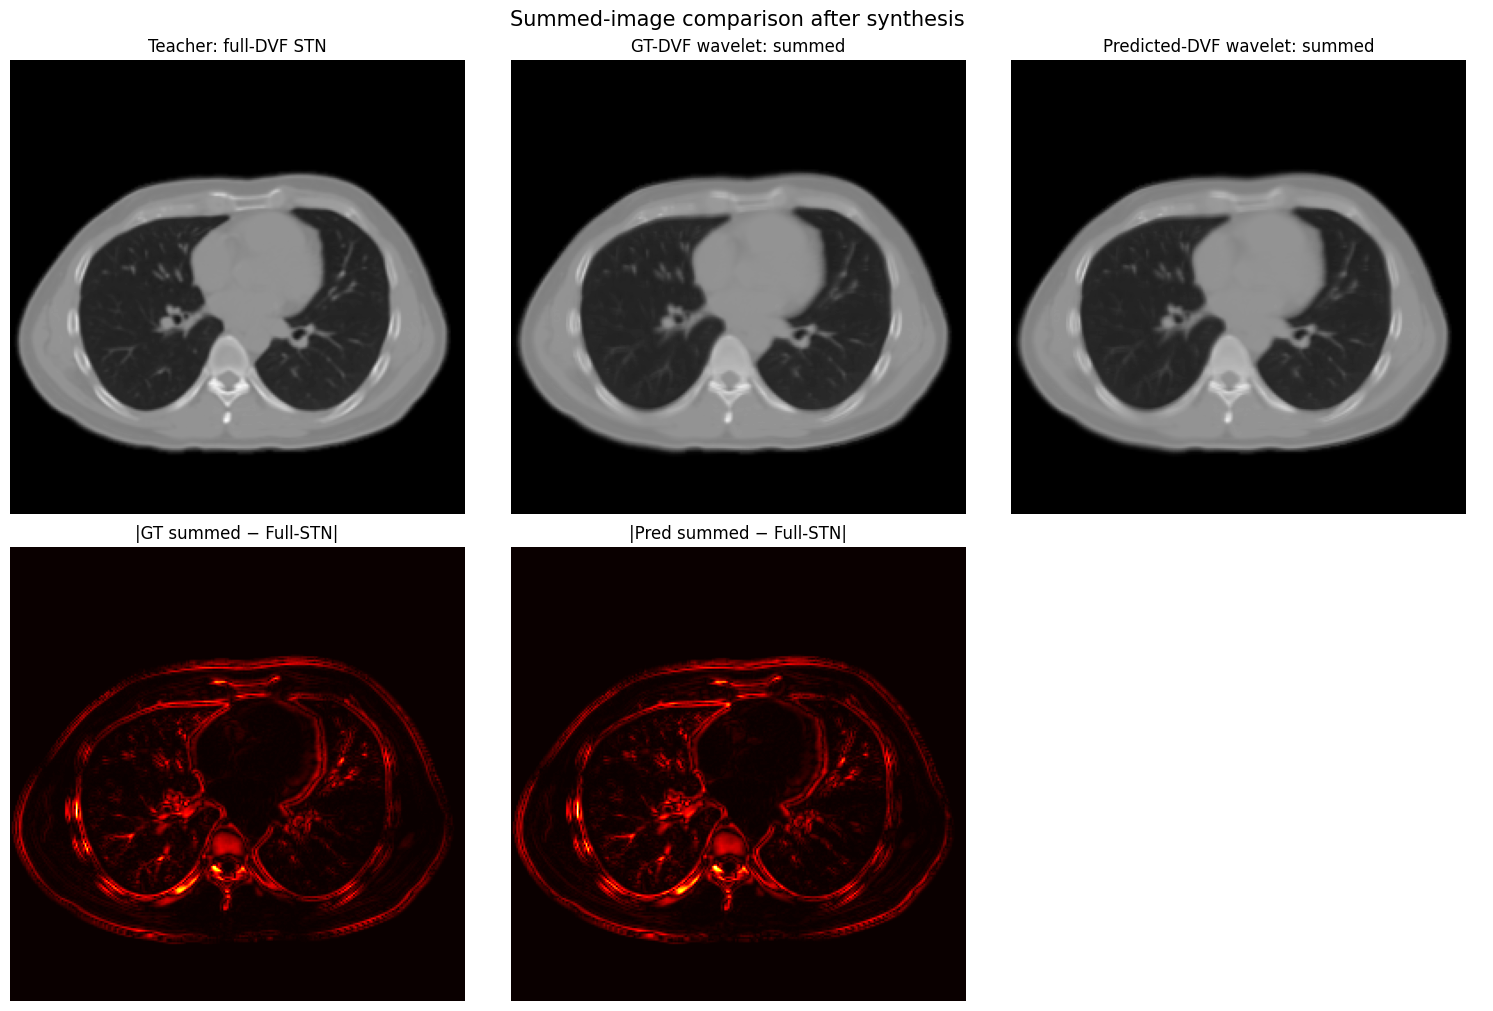

In [42]:
show_summed_comparison(
    teacher_full,
    teacher_wavelet,
    predicted_wavelet,
    OUTPUT_DIR / "09_summed_image_comparison.png",
)

In [43]:
with torch.no_grad():
    moving_w = analysis(moving)

    # STNなしで、そのまま再構成
    moving_up = up_sampling_3d(moving_w)

    reconstructed_no_stn, _ = synthesis_filter_3d(
        moving_up
    )

    print(
        "Analysis → inverse wavelet only MAE:",
        F.l1_loss(
            moving,
            reconstructed_no_stn,
        ).item(),
    )

    print(
        "Analysis → inverse wavelet only RMSE:",
        torch.sqrt(
            F.mse_loss(
                moving,
                reconstructed_no_stn,
            )
        ).item(),
    )

Analysis → inverse wavelet only MAE: 4.034399125885102e-08
Analysis → inverse wavelet only RMSE: 7.175393079705827e-08


In [ ]:
with torch.no_grad():
    zero_flow = torch.zeros(
        1,
        3,
        64,
        128,
        128,
        device=device,
    )

    zero_stn_w = transformer_low(
        moving_w,
        zero_flow,
    )

    zero_stn_up = up_sampling_3d(
        zero_stn_w
    )

    reconstructed_zero_stn, _ = synthesis_filter_3d(
        zero_stn_up
    )

    print(
        "Zero-DVF STN → inverse wavelet MAE:",
        F.l1_loss(
            moving,
            reconstructed_zero_stn,
        ).item(),
    )

Zero-DVF STN → inverse wavelet MAE: 7.490934450515851e-08


: 

In [1]:
# ============================================================
# Full-DVF odd-integer control
#
# full DVFに x方向 +5 px を直接入れる
# Haar round-trip / full-STN / inverse-STN を確認する
#
# 必要な既存定義:
#   x_train
#   transformer256
#   full_dvf_to_wavelet_dvf
#   wavelet_dvf_to_full_dvf
#   DEVICE
# ============================================================

import torch
import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------------------
# Setting
# channel order = [z, y, x]
#
# x方向へ +5 px:
# STN内部では output(z,y,x) = Moving(z,y,x+5)
# なので見た目の画像内容は左へ5px移動する。
# ------------------------------------------------------------

ODD_SHIFT_ZYX = (0, 0, 5)

assert all(
    int(v) == v
    for v in ODD_SHIFT_ZYX
), "整数DVFを入れてください。"


# ------------------------------------------------------------
# Full-resolution constant DVF
# ------------------------------------------------------------

def make_constant_full_dvf(
    batch_size,
    spatial_size,
    shift_zyx,
    device,
):
    """
    shape:
        (B, 3, D, H, W)

    全voxelで同じ整数移動量を持つfull DVF。
    """

    d, h, w = spatial_size

    flow = torch.zeros(
        batch_size,
        3,
        d,
        h,
        w,
        device=device,
        dtype=torch.float32,
    )

    flow[:, 0] = float(shift_zyx[0])  # z
    flow[:, 1] = float(shift_zyx[1])  # y
    flow[:, 2] = float(shift_zyx[2])  # x

    return flow


# ------------------------------------------------------------
# grid_sampleの整数移動に対応する厳密参照画像
#
# padding_mode="border" と同じ端処理
# ------------------------------------------------------------

def integer_shift_reference_border(
    source,
    shift_zyx,
):
    """
    output(z,y,x) = source(
        clamp(z+dz),
        clamp(y+dy),
        clamp(x+dx)
    )
    """

    _, _, d, h, w = source.shape
    dz, dy, dx = shift_zyx

    z_index = torch.clamp(
        torch.arange(d, device=source.device) + dz,
        0,
        d - 1,
    ).long()

    y_index = torch.clamp(
        torch.arange(h, device=source.device) + dy,
        0,
        h - 1,
    ).long()

    x_index = torch.clamp(
        torch.arange(w, device=source.device) + dx,
        0,
        w - 1,
    ).long()

    return (
        source
        .index_select(2, z_index)
        .index_select(3, y_index)
        .index_select(4, x_index)
    )


# ------------------------------------------------------------
# 1. Moving image
# ------------------------------------------------------------

moving = x_train[0:1].float().to(DEVICE)

spatial_size = tuple(moving.shape[2:])

full_dvf = make_constant_full_dvf(
    batch_size=1,
    spatial_size=spatial_size,
    shift_zyx=ODD_SHIFT_ZYX,
    device=DEVICE,
)

print("Moving shape:", tuple(moving.shape))
print("Full DVF shape:", tuple(full_dvf.shape))
print(
    "DVF [z, y, x]:",
    full_dvf[0, :, 0, 0, 0].cpu().numpy(),
)


# ------------------------------------------------------------
# 2. DVF: Haar -> inverse Haar
#    24ch coefficient representationを通しても
#    +5 pxが戻るか確認
# ------------------------------------------------------------

with torch.no_grad():
    dvf_wavelet_24ch = full_dvf_to_wavelet_dvf(
        full_dvf
    )

    reconstructed_full_dvf = wavelet_dvf_to_full_dvf(
        dvf_wavelet_24ch
    )

    dvf_roundtrip_mae = torch.mean(
        torch.abs(full_dvf - reconstructed_full_dvf)
    ).item()

    dvf_roundtrip_max_error = torch.max(
        torch.abs(full_dvf - reconstructed_full_dvf)
    ).item()

print("\n=== Full DVF Haar round-trip ===")
print("24ch shape:", tuple(dvf_wavelet_24ch.shape))
print("MAE:", dvf_roundtrip_mae)
print("Max error:", dvf_roundtrip_max_error)
print(
    "Reconstructed DVF [z,y,x]:",
    reconstructed_full_dvf[
        0, :, 64, 128, 128
    ].cpu().numpy(),
)


# ------------------------------------------------------------
# 3. Full-resolution STN
# ------------------------------------------------------------

with torch.no_grad():
    moved_stn = transformer256(
        moving,
        reconstructed_full_dvf,
    )

    # 整数インデックス参照で作った正解画像
    moved_reference = integer_shift_reference_border(
        moving,
        ODD_SHIFT_ZYX,
    )

    stn_vs_integer_reference_mae = torch.mean(
        torch.abs(moved_stn - moved_reference)
    ).item()

    stn_vs_integer_reference_max_error = torch.max(
        torch.abs(moved_stn - moved_reference)
    ).item()

print("\n=== Full-STN integer control ===")
print(
    "STN vs direct integer-index reference MAE:",
    stn_vs_integer_reference_mae,
)
print(
    "STN vs direct integer-index reference max error:",
    stn_vs_integer_reference_max_error,
)


# ------------------------------------------------------------
# 4. Inverse STN check
#
# FOV端は情報が失われるため、
# 移動量ぶんのmarginを除いた内部だけを比較する。
# ------------------------------------------------------------

inverse_dvf = -reconstructed_full_dvf

with torch.no_grad():
    restored = transformer256(
        moved_stn,
        inverse_dvf,
    )

margin_z = abs(ODD_SHIFT_ZYX[0])
margin_y = abs(ODD_SHIFT_ZYX[1])
margin_x = abs(ODD_SHIFT_ZYX[2])

z_slice = (
    slice(margin_z, -margin_z)
    if margin_z > 0 else slice(None)
)

y_slice = (
    slice(margin_y, -margin_y)
    if margin_y > 0 else slice(None)
)

x_slice = (
    slice(margin_x, -margin_x)
    if margin_x > 0 else slice(None)
)

moving_interior = moving[
    :, :, z_slice, y_slice, x_slice
]

restored_interior = restored[
    :, :, z_slice, y_slice, x_slice
]

restore_interior_mae = torch.mean(
    torch.abs(moving_interior - restored_interior)
).item()

restore_interior_max_error = torch.max(
    torch.abs(moving_interior - restored_interior)
).item()

print("\n=== Forward + inverse STN ===")
print("Interior MAE:", restore_interior_mae)
print("Interior max error:", restore_interior_max_error)


# ------------------------------------------------------------
# 5. Visualization
# ------------------------------------------------------------

z_view = moving.shape[2] // 2

moving_np = moving[0, 0, z_view].cpu().numpy()
moved_np = moved_stn[0, 0, z_view].cpu().numpy()
reference_np = moved_reference[0, 0, z_view].cpu().numpy()
restored_np = restored[0, 0, z_view].cpu().numpy()

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

panels = [
    (
        moving_np,
        "Moving",
        "gray",
    ),
    (
        moved_np,
        "Full-STN: full DVF [0,0,+5]",
        "gray",
    ),
    (
        reference_np,
        "Direct integer-index reference",
        "gray",
    ),
    (
        np.abs(moved_np - reference_np),
        "|STN − integer reference|",
        "magma",
    ),
    (
        restored_np,
        "Restored: STN(Moved, [0,0,−5])",
        "gray",
    ),
    (
        np.abs(restored_np - moving_np),
        "|Restored − Moving|",
        "magma",
    ),
]

for ax, (image, title, cmap) in zip(
    axes.flat,
    panels,
):
    ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(
    "Full-resolution odd-integer DVF control: x = +5 px",
    fontsize=15,
)

plt.tight_layout()
plt.show()

NameError: name 'x_train' is not defined